In [28]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt

In [29]:
# step1: define the compounds
mixture = {#'ethanol': {'CH3':1, 'CH2':1, 'OH':1},
        #    'acetone': {'CH3':1, 'CH3CO':1},
        #    'methanol': {'CH3OH':1},
           "A": {'H2O':1},
           #"A": {'CH3OH':1},
           "B": {'CH3':2, 'CH2':2, 'CH':1, 'HCOO':1}
           #'E': {'CH2': 3, 'HCO': 1, 'CH3COO': 1}
           #'E': {'CH3':1, 'CH2':2, 'CH3CO':1, 'CH2O':1}
           #'E': {'CH3':3, 'CH':1, 'CH2COO':1}
           }
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'A': True, 'B': True}

In [30]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac', 'hv']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)
# fix the properties of candidates
pure_props

{'A': {'tc': 646.9999999999999,
  'pc': 220.6400000000002,
  'tb': 373.1499999999999,
  'ac': 0.3448609999999985,
  'hv': 43.9883},
 'B': {'tc': 589.9854577230362,
  'pc': 33.559848008495194,
  'tb': 408.2734535772965,
  'ac': 0.4121268040277704,
  'hv': 27.132}}

In [31]:
# step3: calculate the Antoine coefficients
antoine_params_ini = {}
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props, method='enthalpy_vap')
    print('optimization results was', results['termination_condition'] )
    antoine_params[compound] = {}
    antoine_params_ini[compound] = {}
    # antoine_params_ini[compound]['A'] = results['A0']
    # antoine_params_ini[compound]['B'] = results['B0']
    # antoine_params_ini[compound]['C'] = results['C0']
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']
print(antoine_params_ini)
print(antoine_params)

Characteristic points (T [K], P [bar]): (298.15, 0.028628051297286683), (373.1499999999999, 1.01325), (646.9999999999999, 220.6400000000002)
optimization results was optimal
Characteristic points (T [K], P [bar]): (298.15, 0.05291819233822578), (408.2734535772965, 1.01325), (589.9854577230362, 33.559848008495194)
optimization results was optimal
{'A': {}, 'B': {}}
{'A': {'A': 5.082781262396579, 'B': 1628.8997558336976, 'C': -52.31505537521556}, 'B': {'A': 8.679165908171045, 'B': 7416.714592277029, 'C': 446.8320920221019}}


In [32]:
# step4: perform the vle

# define number of data points
n_data = 100
# set composition
x1 = np.linspace(0, 1, n_data)  # Component 1: 0 to 1
x2 = 1 - x1                     # Component 2: 1 to 0 (complement)
x = np.column_stack([x1, x2])  # Combine into 2D array
# provide nitial guess for temperature
# Extract boiling points
boiling_points = [props['tb'] for props in pure_props.values()]
T_min = min(boiling_points) 
T_max = max(boiling_points)  
T0 = np.linspace(T_min, T_max, n_data)


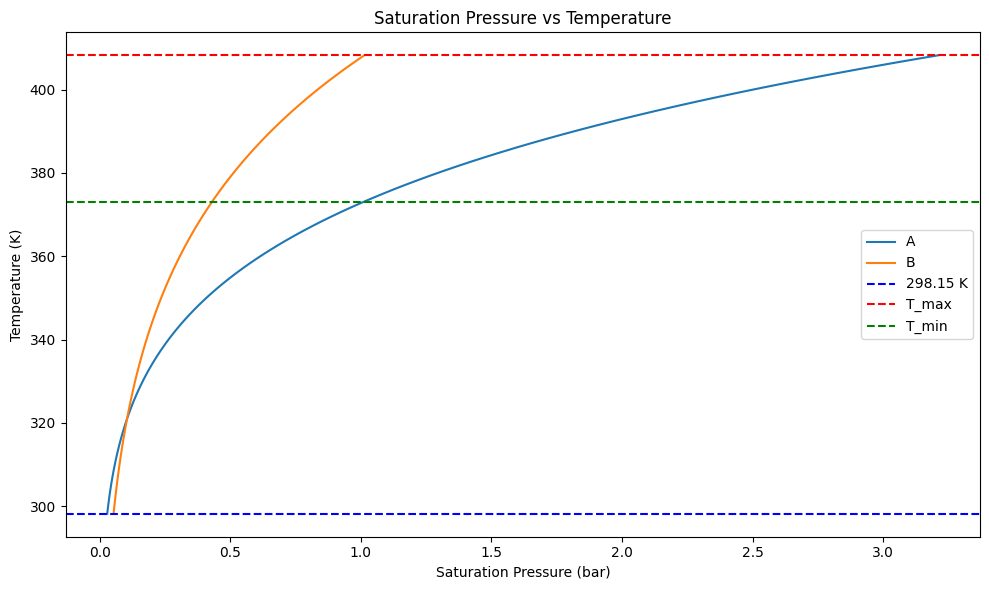

In [33]:
T_range = np.linspace(298.15, T_max, 100)
P_A = antoine_calc.antoine_correlation(A=antoine_params['A']['A'],
                                         B=antoine_params['A']['B'],
                                         C=antoine_params['A']['C'],
                                         T=T_range)
P_B = antoine_calc.antoine_correlation(A=antoine_params['B']['A'],
                                         B=antoine_params['B']['B'],
                                         C=antoine_params['B']['C'],
                                         T=T_range)

# plot the results
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
#plt.plot(P_ac,T_range,  label='Acentric Factor Method')
plt.plot(P_A,T_range, label='A')
plt.plot(P_B,T_range, label='B')
# hilight Tmax, Tmin and 298.15K
plt.axhline(y=298.15, color='b', linestyle='--', label='298.15 K')
plt.axhline(y=T_max, color='r', linestyle='--', label='T_max')
plt.axhline(y=T_min, color='g', linestyle='--', label='T_min')
# add labels and legend
plt.xlabel('Saturation Pressure (bar)')
plt.ylabel('Temperature (K)')
plt.title('Saturation Pressure vs Temperature')
plt.legend()

plt.tight_layout()
plt.show()

model.name="vle";
    - termination condition: infeasible
    - message from solver: Ipopt 3.14.13\x3a Converged to a locally infeasible
      point. Problem may be infeasible.


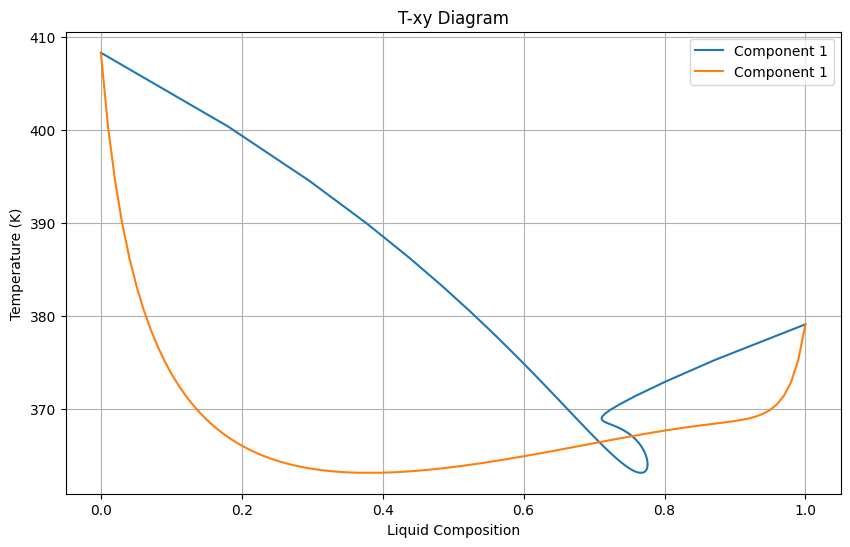

Gamma values:
Component 1: [7.17145257 7.1472725  7.0751327  6.97305629 6.85177032 6.71808202
 6.57652565 6.43023263 6.28142409 6.13170627 5.98225637 5.83394419
 5.68741454 5.5431446  5.40148488 5.26268907 5.12693607 4.99434674
 4.86499653 4.73892529 4.61614494 4.4966454  4.38039943 4.26736633
 4.157495   4.05072639 3.94699543 3.84623264 3.74836541 3.65331902
 3.56101755 3.47138448 3.38434329 3.29981792 3.21773307 3.13801456
 3.06058944 2.98361792 2.91035868 2.84053634 2.77241947 2.70542358
 2.64031825 2.57704272 2.51553807 2.45574724 2.39761502 2.34108803
 2.28611467 2.23264509 2.18063116 2.13002645 2.08078614 2.03286704
 1.9862275  1.94082741 1.89662811 1.85359241 1.8116845  1.77086994
 1.73111563 1.69238977 1.6546618  1.61790245 1.58208362 1.54717842
 1.51316114 1.48000724 1.4476933  1.41619708 1.38549746 1.35557448
 1.32640935 1.29798444 1.27028335 1.24329093 1.21699333 1.19137805
 1.16643405 1.14215185 1.11852364 1.09554341 1.07320722 1.05151335
 1.03046262 1.01005874 0.99030877 0

In [34]:
# step5: lets plot the results in T-xy diagram and inspect the gamma values
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)
# Extract results
# retrieving the solutions
gamma_pyo = np.empty_like(x)
T_pyo = np.empty_like(T0)
y_pyo = np.empty_like(x)
psat_pyo = np.empty_like(x)


for i in model.gamma.keys():
    gamma_pyo[i] = model.gamma[i].value

for i in model.T.keys():
    T_pyo[i] = model.T[i].value

for i in model.y.keys():
    y_pyo[i] = model.y[i].value

for i in model.psat.keys():
    psat_pyo[i] = model.psat[i].value

# Create T-xy plot
plt.figure(figsize=(10, 6))
#for i in range(x.shape[1]):
plt.plot(y_pyo[:, 0], T_pyo,  label=f'Component 1')
plt.plot(x[:, 0], T_pyo,  label=f'Component 1')
plt.ylabel('Temperature (K)')
plt.xlabel('Liquid Composition')
plt.title('T-xy Diagram')
plt.legend()
plt.grid()
plt.show()

# Inspect gamma values
print("Gamma values:")
for i in range(gamma_pyo.shape[1]):
    print(f"Component {i+1}: {gamma_pyo[:, i]}")